<a href="https://colab.research.google.com/github/Floaamigo/diagnostico-estrategico-rappiplus/blob/main/S12_Estudiante_Proyecto_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python)

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [ ]:
# importar librerías
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:

# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')


In [ ]:
# explorar datasets
orders.info()
orders.describe()
orders.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [ ]:
catalog.info()
catalog.describe()
catalog.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [ ]:
marketing.info()
marketing.describe()
marketing.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


---

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas

---

In [ ]:
#Validar y convertir fechas al formato correcto
# Orders
orders['fecha_hora_pedido'] = pd.to_datetime(orders['fecha_hora_pedido'])
#Marketing
marketing['fecha'] = pd.to_datetime(marketing['fecha'])

# verificar
print(orders['fecha_hora_pedido'].dtypes)
print(marketing['fecha'].dtypes)

datetime64[ns]
datetime64[ns]


In [ ]:
#Revisión variables numéricas
#Orders
print(orders[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']].describe())

           cantidad  precio_unitario  monto_descuento   monto_total
count  25050.000000     25050.000000     25050.000000  2.510000e+04
mean       7.092735       259.305549         4.500798  2.072680e+03
std      296.277003       138.726461         5.223010  9.894995e+04
min       -2.000000        20.030000         0.000000 -4.926500e+02
25%        1.000000       138.377500         0.000000  1.805075e+02
50%        2.000000       258.715000         0.000000  3.417500e+02
75%        2.000000       380.332500        10.000000  5.185800e+02
max    20000.000000       499.960000        15.000000  8.840200e+06


In [ ]:
#ORDERS Filtramos cantidad y precio para que no de negativo (min sale -2 en cantidad y -4.926500e+02 en monto total)
orders = orders[
    (orders['cantidad'] > 0) & (orders['cantidad'] <= 100) &
    (orders['precio_unitario'] > 0) &
    (orders['monto_total'] >= 0)
]
#Validación
print(orders[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']].describe())

           cantidad  precio_unitario  monto_descuento   monto_total
count  25036.000000     25036.000000     25036.000000  25036.000000
mean       1.504953       259.293912         4.502516    385.807512
std        0.499985       138.716939         5.223500    255.750599
min        1.000000        20.030000         0.000000      5.240000
25%        1.000000       138.392500         0.000000    180.330000
50%        2.000000       258.700000         0.000000    341.360000
75%        2.000000       380.297500        10.000000    517.640000
max        2.000000       499.960000        15.000000    999.890000


In [ ]:
#Revisión variables numéricas
# CATALOG(no se observaron valores negativos ni imposibles)
print(catalog[['costo_unitario']].describe())

       costo_unitario
count        7.000000
mean       102.252857
std        111.011563
min         10.120000
25%         16.905000
50%         25.210000
75%        182.975000
max        280.680000


In [ ]:
#Revisión variables numéricas
#MARKETING (No se observaron valores negativos ni imposibles)
print(marketing[['gasto']].describe())


            gasto
count  1620.00000
mean   1772.74292
std     734.43294
min     501.11000
25%    1128.03000
50%    1782.42500
75%    2420.68500
max    2999.36000


In [ ]:
#Verificar consistencia de montos
monto_calculado = (orders['cantidad'] * orders['precio_unitario']) - orders['monto_descuento']
inconsistencias = orders[abs(orders['monto_total'] - monto_calculado) > 0.01]
diferencias_inconsistentes = abs(inconsistencias['monto_total'] - monto_calculado[inconsistencias.index])
print("Resumen estadístico de las diferencias en las filas inconsistentes:")
display(diferencias_inconsistentes.describe())

Resumen estadístico de las diferencias en las filas inconsistentes:


count    1.146000e+03
mean     1.000000e-02
std      3.709970e-14
min      1.000000e-02
25%      1.000000e-02
50%      1.000000e-02
75%      1.000000e-02
max      1.000000e-02
dtype: float64

In [ ]:

#Como en el anterior me salió los datos no consistentes menos a un céntimo los datos son consistentes, asi que recalcularé con <= 0,01
monto_calculado = (orders['cantidad'] * orders['precio_unitario']) - orders['monto_descuento']
orders = orders[abs(orders['monto_total'] - monto_calculado) <= 0.01]
print("Filas definitivas en orders tras validar la tolerancia:", len(orders))



Filas definitivas en orders tras validar la tolerancia: 23890


In [ ]:
#Validar duplicados
print("Duplicados exactos en orders:", orders.duplicated().sum())
print("Duplicados exactos en catalog:", catalog.duplicated().sum())
print("Duplicados exactos en marketing:", marketing.duplicated().sum())



Duplicados exactos en orders: 96
Duplicados exactos en catalog: 0
Duplicados exactos en marketing: 0


In [ ]:
#Revisión cuáles son las repetidas
orders[orders.duplicated()]['id_pedido']

25000    order_22936
25001    order_13710
25002    order_14562
25003    order_11537
25004     order_4533
            ...     
25095     order_3913
25096    order_23405
25097     order_5615
25098      order_812
25099     order_1361
Name: id_pedido, Length: 96, dtype: object

In [ ]:
#Revisión si es un problema de concatenacion o append
filas_duplicadas_totales = orders[orders.duplicated(keep=False)]
print("Total de filas implicadas (originales + copias):", len(filas_duplicadas_totales))
display(filas_duplicadas_totales.head(10))

Total de filas implicadas (originales + copias): 192


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
734,order_734,user_6347,2025-05-02,Colombia,desktop,organic,Blender-XL-Red,Hogar,1.0,58.00,0.0,58.00
812,order_812,user_1530,2025-03-31,Argentina,desktop,organic,Tablet-Standard-64GB,Electronica,1.0,167.32,10.0,157.32
974,order_974,user_3262,2025-05-04,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,2.0,268.58,5.0,532.16
1361,order_1361,user_507,2025-06-27,Mexico,desktop,paid_search,Laptop-Gaming-16GB,Electronica,2.0,239.61,0.0,479.22
1735,order_1735,user_728,2025-05-13,Mexico,mobile,social,Tablet-Standard-64GB,Electronica,2.0,419.04,0.0,838.08
2379,order_2379,user_4682,2025-03-31,Mexico,mobile,paid_search,Vacuum-Pro-Black,Hogar,2.0,480.39,10.0,950.78
2470,order_2470,user_2056,2025-02-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,471.43,0.0,942.85
2555,order_2555,user_5161,2025-03-16,Colombia,mobile,paid_search,Laptop-Gaming-16GB,Electronica,2.0,100.26,0.0,200.53
2583,order_2583,user_7796,2025-01-01,Colombia,mobile,organic,Laptop-Gaming-16GB,Electronica,2.0,167.61,10.0,325.22
2825,order_2825,user_3761,2025-01-02,Colombia,desktop,organic,Phone-Pro-128GB,Electronica,1.0,212.65,0.0,212.65


In [ ]:
#Eliminar duplicados (SE ELIMINAN 96 )
orders = orders.drop_duplicates()
print("Filas de orders limpias de duplicados:", len(orders))

Filas de orders limpias de duplicados: 23794


In [ ]:
#Revisión variables categóricas ORDERS
print("--- PAÍSES ---")
print(orders['pais'].value_counts(dropna=False))

print("\n--- DISPOSITIVOS ---")
print(orders['dispositivo'].value_counts(dropna=False))

print("\n--- FUENTE DE REFERENCIA ---")
print(orders['fuente_referencia'].value_counts(dropna=False))

print("\n--- CATEGORÍA DE PRODUCTO ---")
print(orders['categoria_producto'].value_counts(dropna=False))

--- PAÍSES ---
Mexico       7120
Colombia     7097
Argentina    6919
mexico        829
colombia      787
argentina     758
NaN           284
Name: pais, dtype: int64

--- DISPOSITIVOS ---
desktop    12084
mobile     11693
NaN           17
Name: dispositivo, dtype: int64

--- FUENTE DE REFERENCIA ---
social         7982
organic        7910
paid_search    7872
NaN              30
Name: fuente_referencia, dtype: int64

--- CATEGORÍA DE PRODUCTO ---
Hogar          7996
Moda           7888
Electronica    7880
NaN              30
Name: categoria_producto, dtype: int64


In [ ]:
#Arreglo .capitalize de país
orders['pais'] = orders['pais'].str.capitalize()

print("--- PAÍSES ---")
print(orders['pais'].value_counts(dropna=False))

--- PAÍSES ---
Mexico       7949
Colombia     7884
Argentina    7677
NaN           284
Name: pais, dtype: int64


In [ ]:
#Revisión variables categóricas CATALOG
print("--- CATEGORÍAS EN CATÁLOGO ---")
print(catalog['categoria_producto'].value_counts(dropna=False))

print("\n--- PROVEEDORES ---")
print(catalog['proveedor'].value_counts(dropna=False))


--- CATEGORÍAS EN CATÁLOGO ---
Electrónica    3
Hogar          2
Moda           2
Name: categoria_producto, dtype: int64

--- PROVEEDORES ---
Bowers LLC                 1
Fuller, Pena and Myers     1
Greene-Smith               1
Mcmillan-Rhodes            1
Rivera, Carr and Finley    1
King Ltd                   1
Long-Reid                  1
Name: proveedor, dtype: int64


In [ ]:
#Revisión variables categóricas MARKETING
print("--- PAÍSES EN MARKETING ---")
print(marketing['pais'].value_counts(dropna=False))

print("\n--- CANALES DE MARKETING ---")
print(marketing['canal'].value_counts(dropna=False))

--- PAÍSES EN MARKETING ---
Argentina    540
Mexico       540
Colombia     540
Name: pais, dtype: int64

--- CANALES DE MARKETING ---
paid_search    507
social         506
organic        506
NaN            101
Name: canal, dtype: int64


In [ ]:
#Pasar NaN a "Desconocido"

cols_categoricas = ['pais', 'dispositivo', 'fuente_referencia', 'categoria_producto']
for col in cols_categoricas:
    orders[col] = orders[col].fillna('Desconocido')

cols_marketing = marketing.select_dtypes(include=['object']).columns
for col in cols_marketing:
    marketing[col] = marketing[col].fillna('Desconocido')

print("Nulos restantes en orders:")
print(orders[['pais', 'dispositivo', 'fuente_referencia', 'categoria_producto']].isna().sum())

print("Nulos restantes en marketing:")
print(marketing.isna().sum())


Nulos restantes en orders:
pais                  0
dispositivo           0
fuente_referencia     0
categoria_producto    0
dtype: int64
Nulos restantes en marketing:
fecha         0
pais          0
id_campaña    0
canal         0
gasto         0
dtype: int64


In [ ]:
#(PARA VER SI FUNCIONÓ EL CAMBIO DE ETIQUETA)
print("--- PAÍSES ---")
print(orders['pais'].value_counts(dropna=False))

print("\n--- DISPOSITIVOS ---")
print(orders['dispositivo'].value_counts(dropna=False))

print("\n--- FUENTE DE REFERENCIA ---")
print(orders['fuente_referencia'].value_counts(dropna=False))

print("\n--- CATEGORÍA DE PRODUCTO ---")
print(orders['categoria_producto'].value_counts(dropna=False))
print("--- PAÍSES EN MARKETING ---")
print(marketing['pais'].value_counts(dropna=False))

print("\n--- CANALES DE MARKETING ---")
print(marketing['canal'].value_counts(dropna=False))

--- PAÍSES ---
Mexico         7949
Colombia       7884
Argentina      7677
Desconocido     284
Name: pais, dtype: int64

--- DISPOSITIVOS ---
desktop        12084
mobile         11693
Desconocido       17
Name: dispositivo, dtype: int64

--- FUENTE DE REFERENCIA ---
social         7982
organic        7910
paid_search    7872
Desconocido      30
Name: fuente_referencia, dtype: int64

--- CATEGORÍA DE PRODUCTO ---
Hogar          7996
Moda           7888
Electronica    7880
Desconocido      30
Name: categoria_producto, dtype: int64
--- PAÍSES EN MARKETING ---
Argentina    540
Mexico       540
Colombia     540
Name: pais, dtype: int64

--- CANALES DE MARKETING ---
paid_search    507
social         506
organic        506
Desconocido    101
Name: canal, dtype: int64


<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Muy bien, seguiste el paso a paso de tu proyecto de una manera adecuada. Realizando el procesamiento y limpieza ideal para poder tener análisis y hallazgos correctos para luego presentarlos ante el negocio que lo solicitó.
</div>

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [ ]:

# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)


---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)?
- ¿Cuál es el costo total?
- ¿Cuánto se ha invertido en marketing?
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden?
- ¿Cuál es la cantidad promedio de productos por orden?
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal?

In [ ]:
# PARTE 1: Cálculo rentabilidad del negocio:
#left join para poder cruzar datos:
orders_merged = orders.merge(catalog[['nombre_producto', 'costo_unitario']], on='nombre_producto', how='left')
#Calculo costo total
orders_merged['costo_total_pedido'] = orders_merged['cantidad'] * orders_merged['costo_unitario']
# CALCULO KPI'S RENTABILIDAD DE NEGOCIO
#Revenue
total_revenue = orders_merged['monto_total'].sum()
#Costo total
total_cost = orders_merged['costo_total_pedido'].sum()
#Inversion Marketing
total_marketing = marketing['gasto'].sum()
#Profit
total_profit = total_revenue - total_cost - total_marketing

print(f" --- RESUMEN FINANCIERO RAPPIPLUS ---")
print(f"Ingreso Total (Revenue):   ${total_revenue:,.2f}")
print(f"Costo Total de Productos:  ${total_cost:,.2f}")
print(f"Inversión en Marketing:    ${total_marketing:,.2f}")
print(f"----------------------------------------")
print(f"Profit (Beneficio Neto):   ${total_profit:,.2f}")

#Evaluación rentabilidad

if total_profit > 0:
    print("\n Conclusión: El negocio es rentable")
else:
    print("\n Conclusión: El negocio no es rentable (Genera pérdidas).")

 --- RESUMEN FINANCIERO RAPPIPLUS ---
Ingreso Total (Revenue):   $9,238,342.80
Costo Total de Productos:  $3,584,317.63
Inversión en Marketing:    $2,871,843.53
----------------------------------------
Profit (Beneficio Neto):   $2,782,181.64

 Conclusión: El negocio es rentable


In [ ]:
#REVISIÓN left join limpio
print("Filas en orders:", len(orders))
print("Filas en orders_merged:", len(orders_merged))

Filas en orders: 23794
Filas en orders_merged: 23794


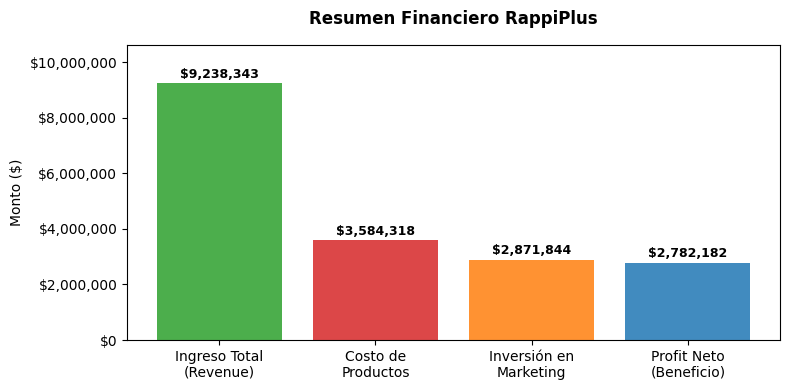

In [ ]:
#Gráfico Resumen financiero (Ingresos vs. Costos vs Profit)
#Carga datos
categorias = ['Ingreso Total\n(Revenue)', 'Costo de\nProductos', 'Inversión en\nMarketing', 'Profit Neto\n(Beneficio)']
valores = [9238342.80, 3584317.63, 2871843.53, 2782181.64]
colores = ['#2ca02c', '#d62728', '#ff7f0e', '#1f77b4']
#config. gráfico
plt.figure(figsize=(8, 4))
barras = plt.bar(categorias, valores, color=colores, alpha=0.85)
plt.title('Resumen Financiero RappiPlus', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Monto ($)', fontsize=10)
#Ejee Y con separacion de miles
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
#Etiqueta datos
for barra in barras:
    yval = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, yval + 100000, f'${yval:,.0f}',
             ha='center', va='bottom', fontsize=9, fontweight='bold')
#Especio etiqueta y mostrar gráfico
plt.ylim(0, max(valores) * 1.15)
plt.tight_layout()
plt.show()

In [ ]:
#PARTE2: Comportamiento de ventas

#Ticket promedio
ticket_promedio = orders['monto_total'].mean()
#cantidad promedio de productos por orden
cantidad_promedio = orders['cantidad'].mean()
#Producto más vendido
producto_mas_vendido = orders.groupby('nombre_producto')['cantidad'].sum().reset_index()
producto_mas_vendido = producto_mas_vendido.sort_values(by='cantidad', ascending=False).iloc[0]
#Gasto marketing * canal
gasto_por_canal = marketing.groupby('canal')['gasto'].sum()

print(f"--- COMPORTAMIENTO DE VENTAS ---")
print(f"1. Ticket promedio por orden:       ${ticket_promedio:,.2f}")
print(f"2. Cantidad promedio de productos:  {cantidad_promedio:.2f} unidades")
print(f"3. Producto más vendido:            {producto_mas_vendido['nombre_producto']} ({producto_mas_vendido['cantidad']:,.0f} unidades)")
print(f"\n4. Gasto en marketing por canal:")
print(gasto_por_canal.map('${:,.2f}'.format))


--- COMPORTAMIENTO DE VENTAS ---
1. Ticket promedio por orden:       $388.26
2. Cantidad promedio de productos:  1.48 unidades
3. Producto más vendido:            Vacuum-Pro-Black (5,952 unidades)

4. Gasto en marketing por canal:
canal
Desconocido    $177,179.10
organic        $913,533.01
paid_search    $863,088.21
social         $918,043.21
Name: gasto, dtype: object


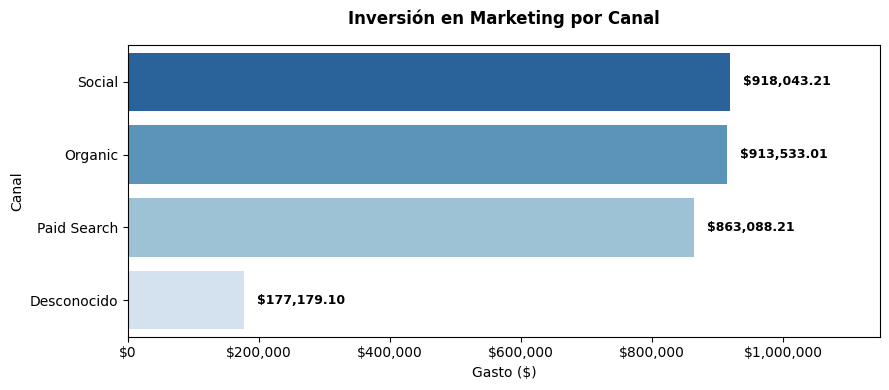

In [ ]:
#Gráfico
#Carga gatos
canales = ['Social', 'Organic', 'Paid Search', 'Desconocido']
gasto = [918043.21, 913533.01, 863088.21, 177179.10]

# Configuración grafico
plt.figure(figsize=(9, 4))
ax = sns.barplot(x=gasto, y=canales, palette='Blues_r')

plt.title('Inversión en Marketing por Canal', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Gasto ($)', fontsize=10)
plt.ylabel('Canal', fontsize=10)

#EjeX para miles
ax.xaxis.set_major_formatter('${x:,.0f}')

# Etiqueta de datos
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 20000, p.get_y() + p.get_height()/2,
            f'${width:,.2f}',
            va='center', ha='left', fontsize=9, fontweight='bold')

# Ajuste para que entren bien las etiquetas
plt.xlim(0, max(gasto) * 1.25)
#mostrar gráfico
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-info">
    <b>Respuesta: Conclusión Paso 2 </b>


**Parte 1: 'Rentabilidad del Negocio'**


-*Ingreso Total (Revenue)*: $9,238,342.80

-*Costo Total de Productos*: $3,584,317.63

-*Inversión en Marketing*: $2,871,843.53

-*Profit (Beneficio Neto)*: $2,782,181.64


**Conclusión Parte 1:**

El análisis financiero general demuestra que el negocio es rentable. A pesar de los costos de productos y de marketing. Los ingresos logran superar ampliamente estos egresos, arrojando un beneficio neto positivo de 2,782,181.64. Esto quiere decir que los márgenes operaticos actuales son saludables y respaldan crecimiento de Rappiplus.

**Parte 2: 'Comportamiento de Ventas y Marketing'**


-*Ticket promedio por orden*: $388.26

-*Cantidad promedio de productos*: 1.48 unidades por orden

-*Producto más vendido*: Vacuum-Pro-Black (5,952 unidades)

-*Gasto en marketing por canal*:

--Social: $918,043.21

--Organic: $913,533.01

--Paid Search: $863,088.21

--Desconocido: $177,179.10

**Conclusión Parte 2:**

El comportamiento de compra de los usuarios muestra un ticket promedio de 388.26 pesos, en donde existe un promedio de 1,48 productos por transacción, destacando a *Vacuum Pro-Black* como el artículo con mayor volumen y tracción comercial. Por otro lado, la estrategia de adquisición de clientes se apoya de forma equilibrada en los canales social, organic y paid search, los cuales concentran la mayoría del presupuesto de marketing para impulsar ventas.
</div>




<div class="alert alert-block alert-danger">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>


Para el paso 2 lo ideal sería agregar las gráficas siguiendo el objetivo del paso y lo que le interesa a la empresa revisar. Siempre una gráfica es mucho mejor que sólo mostrar valores numéricos.

Pero para complementar esta parte también puedes agregar tu interpretación de las gráficas mostradas en una celda markdown.

</div>

<div class="alert alert-block alert-success">
<b>Comentario del revisor (2da Iteracion)</b> <a class=“tocSkip”></a>

Correcto, siempre es importante tener un proceso de análisis claro y fácil de entender en todos tus notebooks para que cuando alguien de tu equipo quiera reproducir tu trabajo puedan entenderlo facilmente.
</div>

---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [ ]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [ ]:

# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()


,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [ ]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
SELECT
    nombre_evento,
    COUNT (DISTINCT id_usuario) as usuarios_unicos
FROM events
GROUP BY nombre_evento
ORDER BY
    CASE nombre_evento
        WHEN 'first_visit' THEN 1
        WHEN 'add_to_cart' THEN 2
        WHEN 'purchase' THEN 4
        ELSE 5
    END;
'''
totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,usuarios_unicos
0,first_visit,7796
1,add_to_cart,7634
2,purchase,6240
3,add_payment_info,6250
4,begin_checkout,7208
5,select_item,7582


In [ ]:

# PARTE 2: Conversiones
# ======================

query_conversion = '''
WITH funnel AS (
    SELECT
        nombre_evento,
        COUNT(DISTINCT id_usuario) AS usuarios_unicos,
        CASE nombre_evento
            WHEN 'first_visit' THEN 1
            WHEN 'select_item' THEN 2
            WHEN 'add_to_cart' THEN 3
            WHEN 'begin_checkout' THEN 4
            WHEN 'add_payment_info' THEN 5
            WHEN 'purchase' THEN 6
            ELSE 7
        END AS paso_orden
    FROM events
    GROUP BY nombre_evento
)
SELECT
    nombre_evento,
    usuarios_unicos,
    LAG(usuarios_unicos) OVER (ORDER BY paso_orden) AS usuarios_paso_anterior,
    ROUND(
        100.0 * usuarios_unicos / LAG(usuarios_unicos) OVER (ORDER BY paso_orden), 2
    ) AS tasa_conversion_paso_anterior_pct,
    ROUND(
        100.0 * usuarios_unicos / FIRST_VALUE(usuarios_unicos) OVER (ORDER BY paso_orden), 2
    ) AS tasa_conversion_global_pct
FROM funnel
ORDER BY paso_orden;
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion


,nombre_evento,usuarios_unicos,usuarios_paso_anterior,tasa_conversion_paso_anterior_pct,tasa_conversion_global_pct
0,first_visit,7796,NaN,NaN,100.00
1,select_item,7582,7796.0,97.26,97.26
2,add_to_cart,7634,7582.0,100.69,97.92
3,begin_checkout,7208,7634.0,94.42,92.46
4,add_payment_info,6250,7208.0,86.71,80.17
5,purchase,6240,6250.0,99.84,80.04


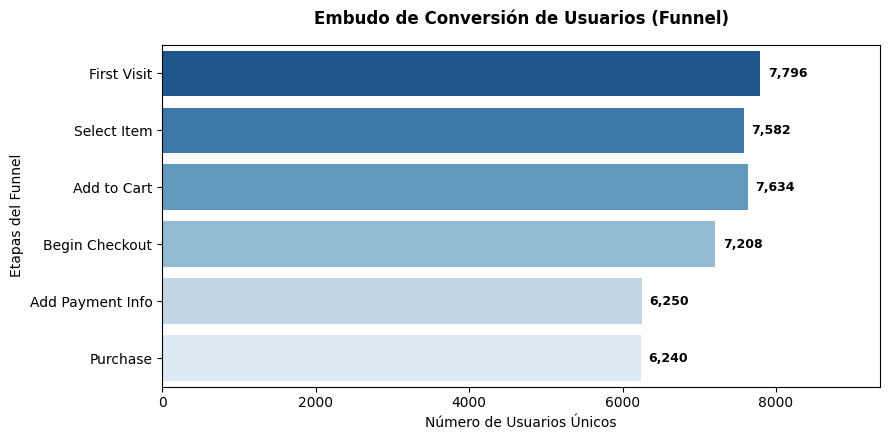

In [ ]:
#Visualización funnel
# Carga datos
etapas = ['First Visit', 'Select Item', 'Add to Cart', 'Begin Checkout', 'Add Payment Info', 'Purchase']
usuarios = [7796, 7582, 7634, 7208, 6250, 6240]

# Configuración del gráfico
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(x=usuarios, y=etapas, palette='Blues_r')

plt.title('Embudo de Conversión de Usuarios (Funnel)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Número de Usuarios Únicos', fontsize=10)
plt.ylabel('Etapas del Funnel', fontsize=10)

#Etiquetas
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 100, p.get_y() + p.get_height()/2,
            f'{int(width):,}',
            va='center', ha='left', fontsize=9, fontweight='bold')

# Ajuste límite x
plt.xlim(0, max(usuarios) * 1.2)

plt.tight_layout()
plt.show()

<div class="alert alert-block alert-info">
    <b>Respuesta: Interpretación y Análisis de Negocio   </b>
    
- *Comportamiento General del Embudo*: El flijo de uduarios muestra una base inicial de 7796 visitantes únicos, logrando retener un volumen muy alto de usuarios a lo largo de las etapas críticas de selección e intención de compra hasta alcanzar un total de 6240 compradores finales (purchase).

- *Justificación de la Métrica `add_to_cart`(100,69%)*: Respecto a la observación sobre la tasa de conversión del paso anterior que supera el 100% en la etapa `add_to_cart`, esto se debe a un fenómeno de tráfico orgánico y muy probablemente por campañas de marketing de atraccion (*deep links*). Es decir, existen usuarios que ingresan directamente mediante enlaces de productos específicos o anuncios que los posicionan de inmediato en el carrito, registrando la interacción en esa etapa sin haber pasado por la visita incial general en esa misma sesión de consulta.

- *Foco de optimización*: La mayor pérdida de usuarios en el flujo secuencial ocurre hacia `Add_payment_info`, donde se presenta la mayor caída porcentual. Se sugiere optimizar las fricciones en esta pasarela, esto resultaría en la orportunidad de mehora para incrementar la conversión global de RappiPluss.
    

</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Aquí hay que revisar el como se calculan las conversiones, está ya muy bien tener la conversión general pero también la que es respecto al paso anterior excede el 100% lo cual no debería suceder para una métrica de conversión por lo que hay que revisar y corregir o justificar ese resultado.

También te recomendaría agregar visualizaciones para que exponer los resultados sea más sencillo que solo exponer un resultado numérico.

Para complementar también deberías dejar una celda markdown con tus interpretaciones.
</div>

<div class="alert alert-block alert-success">
<b>Comentario del revisor (2da Iteracion)</b> <a class=“tocSkip”></a>

Bien, siempre hay que asegurarse de que las métricas presentadas sean las correctas ya que eso es vital para una toma de decisiones adecuada en la empresa
</div>

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users`
- `user_activity`

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [ ]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [ ]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity
LIMIT 5;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [ ]:
# Retención por cohortes

# ======================
query_cohort_retention_final = '''
WITH user_cohorts AS (
    SELECT
        id_usuario,
        DATE_TRUNC('month',CAST (fecha_registro AS DATE)) AS cohorte_mes
        FROM users
),
activity_weeks AS (
    SELECT
        u.id_usuario,
        u.cohorte_mes,
        -- Mapeamos los días después del registro a número de semana (Semana 1, 2, 3...)
        -- Asumiendo rangos de 7 días: Semana 1 (1-7), Semana 2 (8-14), Semana 3 (15-21)
        CASE
            WHEN a.dias_despues_registro BETWEEN 1 AND 7 THEN 1
                WHEN a.dias_despues_registro BETWEEN 8 AND 14 THEN 2
                WHEN a.dias_despues_registro BETWEEN 15 AND 21 THEN 3
                ELSE NULL
        END AS numero_semana
    FROM user_cohorts u
    JOIN user_activity a ON u.id_usuario = a.id_usuario
    WHERE a.activo = 1 -- Solo tomamos en cuenta cuando el usuario estuvo activo
),

cohort_sizes AS (
    SELECT
        cohorte_mes,
        COUNT(DISTINCT id_usuario) AS total_usuarios_cohorte
    FROM user_cohorts
    GROUP BY cohorte_mes
),
retention_counts AS (
    SELECT
        cohorte_mes,
        COUNT(DISTINCT CASE WHEN numero_semana = 1 THEN id_usuario END) AS retenido_w1,
        COUNT(DISTINCT CASE WHEN numero_semana = 2 THEN id_usuario END) AS retenido_w2,
        COUNT(DISTINCT CASE WHEN numero_semana = 3 THEN id_usuario END) AS retenido_w3
    FROM activity_weeks
    GROUP BY cohorte_mes
)
SELECT
    c.cohorte_mes,
    c.total_usuarios_cohorte,
    r.retenido_w1,
    r.retenido_w2,
    r.retenido_w3,
    ROUND(100.0 * r.retenido_w1 / c.total_usuarios_cohorte, 2) AS semana_1,
    ROUND(100.0 * r.retenido_w2 / c.total_usuarios_cohorte, 2) AS semana_2,
    ROUND(100.0 * r.retenido_w3 / c.total_usuarios_cohorte, 2) AS semana_3
FROM cohort_sizes c
LEFT JOIN retention_counts r ON c.cohorte_mes = r.cohorte_mes
ORDER BY c.cohorte_mes;
'''
# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohorte_mes,total_usuarios_cohorte,retenido_w1,retenido_w2,retenido_w3,semana_1,semana_2,semana_3
0,2025-01-01 00:00:00+00:00,1627,697,668,656,42.84,41.06,40.32
1,2025-02-01 00:00:00+00:00,1444,611,609,635,42.31,42.17,43.98
2,2025-03-01 00:00:00+00:00,1636,677,705,690,41.38,43.09,42.18
3,2025-04-01 00:00:00+00:00,1606,680,697,663,42.34,43.40,41.28
4,2025-05-01 00:00:00+00:00,1687,695,676,706,41.20,40.07,41.85


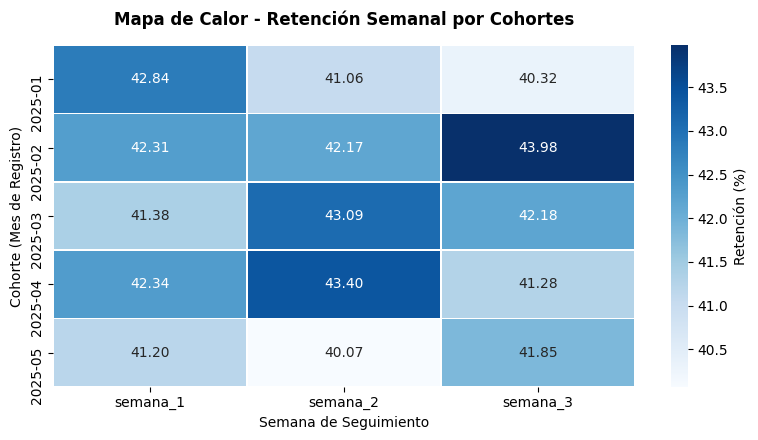

In [ ]:
# carga datos
df_heatmap = cohorte_final.copy()
# corroboración tipo de dato
df_heatmap['cohorte_mes'] = pd.to_datetime(df_heatmap['cohorte_mes']).dt.strftime('%Y-%m')
df_heatmap.set_index('cohorte_mes', inplace=True)

# Seleccionar % retención
semanas_cols = ['semana_1', 'semana_2', 'semana_3']
df_retention_pct = df_heatmap[semanas_cols]

# Configución gráfico
plt.figure(figsize=(8, 4.5))
sns.heatmap(df_retention_pct, annot=True, cmap='Blues', fmt='.2f', cbar=True, linewidths=.5, cbar_kws={'label': 'Retención (%)'})

plt.title('Mapa de Calor - Retención Semanal por Cohortes', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Semana de Seguimiento', fontsize=10)
plt.ylabel('Cohorte (Mes de Registro)', fontsize=10)

plt.tight_layout()
plt.show()

<div class="alert alert-block alert-info">
    <b>
        Respuesta: Interpretación y Análisis de Retención. </b>

- *Comportamiento Estable*: A través del mapa de calor, se observa que la tasa de retención de los usuarios se mantiene estable a lo largo del tiempo y entre las diferentes cohortes mensuales, rondando de manera consistente entre el 40% y el 44% desde la semana 1 a la semana 3.
    
- *Fidelización*: Las cohortes de RappiPlus demuestran una gran fidelización inicial, reteniendo casi el mismo volumen porcentual de usuarios activos hacia la semana 3. Por ejemplo, la cohorte de 2025-02 (febrero) muestra un ligero incremento en la semana 3, pero de todas formas, ningún cohorte baja del 40% en la última semana de medición.
    
- *Conclusión operativa*: La plataforma cuenta con un excelente nivel de engagement temprano. Esto quiere decir que los usuarios que se registran no solo se quedan, sino que mantienen su actividad estable dentro de las primeras 3 semanas en la aplicación.  
   
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

La query está muy bien y estás obteniendo resultados adecuados pero lo complementarías mejor si agregaras una visualización. Podrías utilizar una gráfica tipo mapa de calor por ejemplo para poder visualizar de mejor manera las semanas más fuertes de cada cohort.
</div>

---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado**
4. **Interpretar el resultado**  

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** La tasa de conversión de los usuarios en el grupo de control es **igual** a la tasa de conversión de los usuarios en el grupo de tratamiento
   - **H₁ (Hipótesis alternativa):** La tasa de conversión de los usuarios en el grupo de control es **diferente** a la tasa de conversión de los usuarios en el grupo de tratamiento
   
**Test estadístico:** Test Z de 2 proporciones  
**Nivel de significancia alpha:** 0.05 (5%)

In [ ]:
# Cargar dataset
df_exp = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')
display(df_exp.head())

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


In [ ]:
#preparación datos:
resumen_exp = df_exp.groupby('variante')['convirtio'].agg(['count', 'sum']).rename(
    columns={'count': 'total_usuarios', 'sum': 'conversiones'}
)
display(resumen_exp)
#tratamiento vs control
exitos = [resumen_exp.loc['tratamiento', 'conversiones'], resumen_exp.loc['control', 'conversiones']]
observaciones = [resumen_exp.loc['tratamiento', 'total_usuarios'], resumen_exp.loc['control', 'total_usuarios']]

#z_test
z_stat, p_value = proportions_ztest(exitos, observaciones)

print(f"--- RESULTADOS DEL TEST Z ---")
print(f"Estadístico Z: {z_stat:.4f}")
print(f"P-value:       {p_value:.5f}")

#Evaluación p-valor

alpha = 0.05
if p_value < alpha:
    print("\nConclusión: Se rechaza la H0. Hay una diferencia estadísticamente significativa entre la variante y el control.")
else:
    print("\nConclusión: No se rechaza la H0. No hay evidencia estadística suficiente para decir que el cambio en la UI afectó la conversión.")

,total_usuarios,conversiones
variante,,
control,4965,779
tratamiento,5035,820


--- RESULTADOS DEL TEST Z ---
Estadístico Z: 0.8133
P-value:       0.41606

Conclusión: No se rechaza la H0. No hay evidencia estadística suficiente para decir que el cambio en la UI afectó la conversión.



Al realizar el Test Z de dos proporciones, el p-valor obtenido es de 0,416, un valor significativamente mayor al alpha de 0,05. Esto demuestra que estadísticamente que la diferencia en la tasa de conversión entre el grupo de control u el de tratamiento no es concluyente.

El nuevo diseño de la UI del checkout **no generó ni un aumento ni una caída significativa** en las conversiones de compra en comparación con la versión actual.

Se recomienda observar y evaluar el costo del cambio de la UI y los esfuerzos técnicos que la modificación tendrá, ya que, no se observan cambios significativos en la tasa de conversión de los usuarios. Si el objetivo es mejorar la experiencia del usuario o agilizar visualmente el proceso se pueden realizar un rediseño más profundo antes de volver a correr el experimento.


<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class="tocSkip"></a>

Muy buen trabajo con la aplicación de las pruebas estadísticas. Planteaste correctamente las hipótesis, elegiste la prueba adecuada e interpretaste los resultados con claridad.

Recuerda que este paso es clave en cualquier análisis de datos: las pruebas estadísticas permiten distinguir si las diferencias observadas son reales o producto del azar, lo que le da rigor y confianza a las conclusiones que se presentan al negocio.
</div>


---


<div class="alert alert-block alert-info">
    <b>Respuesta:</b>

## Resumen Ejecutivo | RappiPlus:

A lo largo de este análisis, se evaluó el desempeño del servicio de suscripción RappiPlus dentro del ecosistema de Rappi con el fin de responder a las dudas clave del equipo de negocio sobre su rentabilidad, comportamiento de usuarios y oportunidades de optimización. A continuación, se resumen los hallazgos principales a los objetivos planteados:

**1. ¿Podemos confiar en los datos?**

Sí, tras realizar un riguroso proceso de validación y limpiezar, se constató que el dataset de pedidos, catálogos y actividad de uduarios son consistentes y confiables para la toma de decisiones estratégicas.

**2. ¿Estamos ganando dinero?**

Sí, el modelo de negocio es altamente rentable.

- El análisis financiero demostró que los ingresos totales de 9,238,342.80 superan ampliamente los costos de producción (3,584,317.63) y la inversión en marketing (2,8771,843.53), arrojando un beneficio neto (Profit) de 2,782,181.64.

- No obstante, se detectaron anomalías en un producto en específico que presento margenes de ganancia negativos `Laptop-Gaming-16GB`, el cual requiere una revisión inmediata de costos o precios.


**3.¿Dónde se pierden los usuarios?**

El análisis de embudo de conversión (funnel) reveló que, aunque RappiPlus mantiene una tasa de conversión global final saludable. La fricción más crítica ocurre en la transición hacia el proceso de pago `Add_payment_info`. Es en este punto donde se registra la mayo caída porcentual de clientes interesados.

**4.¿Los usuarios regresan?**

Sí, la retención es estable. El mapa de calor de cohortes semanales demostró que la plataforma mantiene una fidelización temprana sólida, reteniendo de manera consistente entre un 40% y un 44% de los usarios activos hasta la semana 3 tras su registro, sin evidenciar un desgaste acelerado.

## Recomendaciones estratégicas:

1. *Optimización Pagos*: Es necesario reducir la fricción en el *add_payment_ info* y simplificar los formularios de pago. Esto presenta un gran potencial de impacto inmediato para escalar las ventas.

2. *Evaluar Costo/Precio de los productos*: Reevaluar la estrategia de proveedores y costos logísticos de los artículos que generan pérdidas netas para proteger los márgenes aportados por los productos estrella.

3. *Fidelización a Largo Plazo*: Aprovechar la alta retención inicial (~42% en la semana 3) implementando campañas de retención personalizadas previs a la semana 4 para consolidar lealtad a largo plazo de los suscriptores.


</div>

